# L2 Sigma Timing Analysis
Visualize per-event timing from the EDR detection pipeline.

In [1]:
import json
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

plt.rcParams.update({
    'figure.facecolor': '#0d1117',
    'axes.facecolor':   '#161b22',
    'axes.edgecolor':   '#30363d',
    'axes.labelcolor':  '#c9d1d9',
    'xtick.color':      '#8b949e',
    'ytick.color':      '#8b949e',
    'text.color':       '#c9d1d9',
    'grid.color':       '#21262d',
    'grid.linewidth':   0.5,
    'font.family':      'monospace',
    'axes.titlecolor':  '#f0f6fc',
    'axes.titlesize':   13,
    'axes.titleweight': 'bold',
})

C_FRESH    = '#388bfd'
C_CACHE    = '#f78166'
C_MATCHED  = '#3fb950'
C_NO_MATCH = '#484f58'
C_AVG      = '#d29922'
C_MIN      = '#3fb950'
C_MAX      = '#f85149'

print('Setup complete.')

Setup complete.


In [3]:
# ── Change this to your file path ─────────────────────────────────────────
FILE_PATH = 'l2_timing_hash_20260507_213818.json'

with open(FILE_PATH) as f:
    data = json.load(f)

records  = data['records']
summary  = data['summary']
label    = data['label']

x         = list(range(len(records)))
elapsed   = [r['elapsed_ms'] for r in records]
cache_hit = [r['cache_hit']  for r in records]
matched   = [r['matched']    for r in records]

hits      = [r for r in records if     r['cache_hit']]
fresh     = [r for r in records if not r['cache_hit']]
ruled     = [r for r in records if     r['matched']]

avg_hits  = sum(r['elapsed_ms'] for r in hits)  / max(len(hits),  1)
avg_fresh = sum(r['elapsed_ms'] for r in fresh) / max(len(fresh), 1)

print(f'Loaded  : {FILE_PATH}')
print(f'Label   : {label}')
print(f'Records : {len(records)}')

Loaded  : l2_timing_hash_20260507_213818.json
Label   : hash
Records : 1574


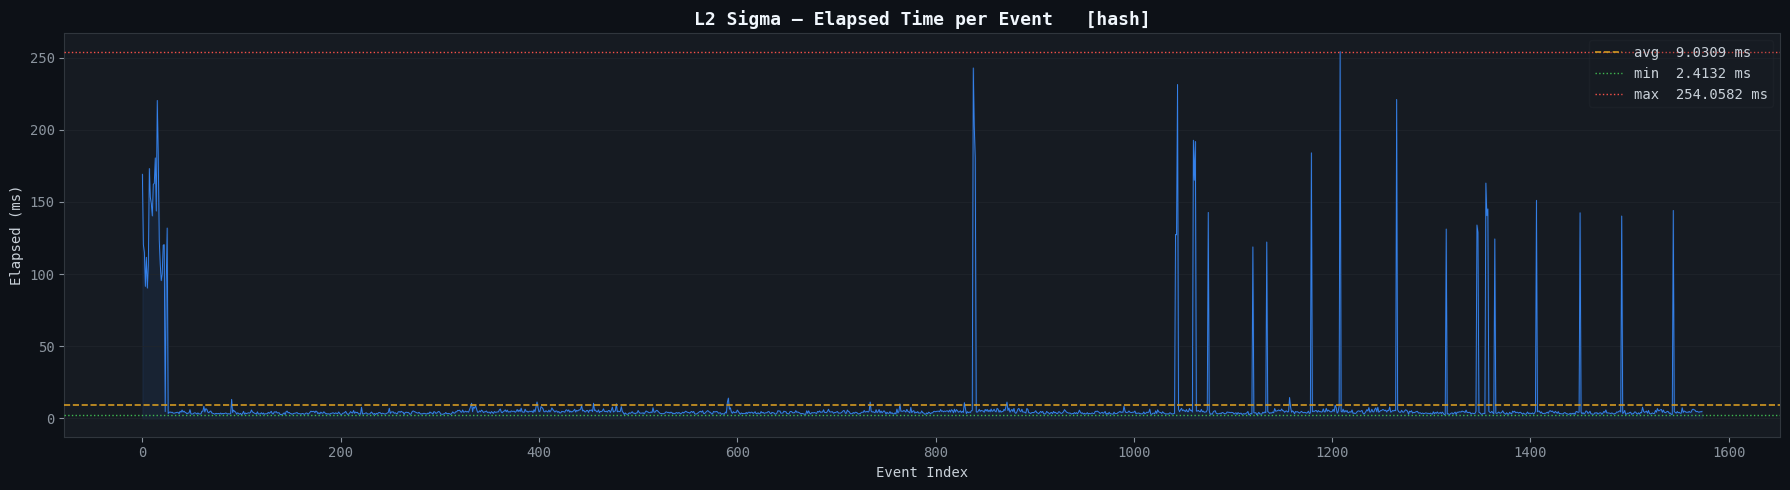

In [4]:
# ── Plot 1 — Raw elapsed time ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(18, 5))

ax.plot(x, elapsed, linewidth=0.7, color=C_FRESH, alpha=0.9, zorder=2)
ax.fill_between(x, elapsed, alpha=0.08, color=C_FRESH)

ax.axhline(summary['l2_avg_time_ms'], color=C_AVG, linestyle='--', linewidth=1.2,
           label=f"avg  {summary['l2_avg_time_ms']} ms", zorder=3)
ax.axhline(summary['l2_min_time_ms'], color=C_MIN, linestyle=':', linewidth=1.0,
           label=f"min  {summary['l2_min_time_ms']} ms", zorder=3)
ax.axhline(summary['l2_max_time_ms'], color=C_MAX, linestyle=':', linewidth=1.0,
           label=f"max  {summary['l2_max_time_ms']} ms", zorder=3)

ax.set_xlabel('Event Index')
ax.set_ylabel('Elapsed (ms)')
ax.set_title(f'L2 Sigma — Elapsed Time per Event   [{label}]')
ax.legend(framealpha=0.2, edgecolor='#30363d')
ax.grid(True, axis='y')
fig.tight_layout()
plt.show()

In [11]:
# ── Change this to your file path ─────────────────────────────────────────
FILE_PATH = 'l2_timing_before hash_20260507_211000.json'

with open(FILE_PATH) as f:
    data = json.load(f)

records  = data['records']
summary  = data['summary']
label    = data['label']

x         = list(range(len(records)))
elapsed   = [r['elapsed_ms'] for r in records]
matched   = [r['matched']    for r in records]



ruled     = [r for r in records if     r['matched']]

avg_hits  = sum(r['elapsed_ms'] for r in hits)  / max(len(hits),  1)
avg_fresh = sum(r['elapsed_ms'] for r in fresh) / max(len(fresh), 1)

print(f'Loaded  : {FILE_PATH}')
print(f'Label   : {label}')
print(f'Records : {len(records)}')

Loaded  : l2_timing_before hash_20260507_211000.json
Label   : before hash
Records : 1574


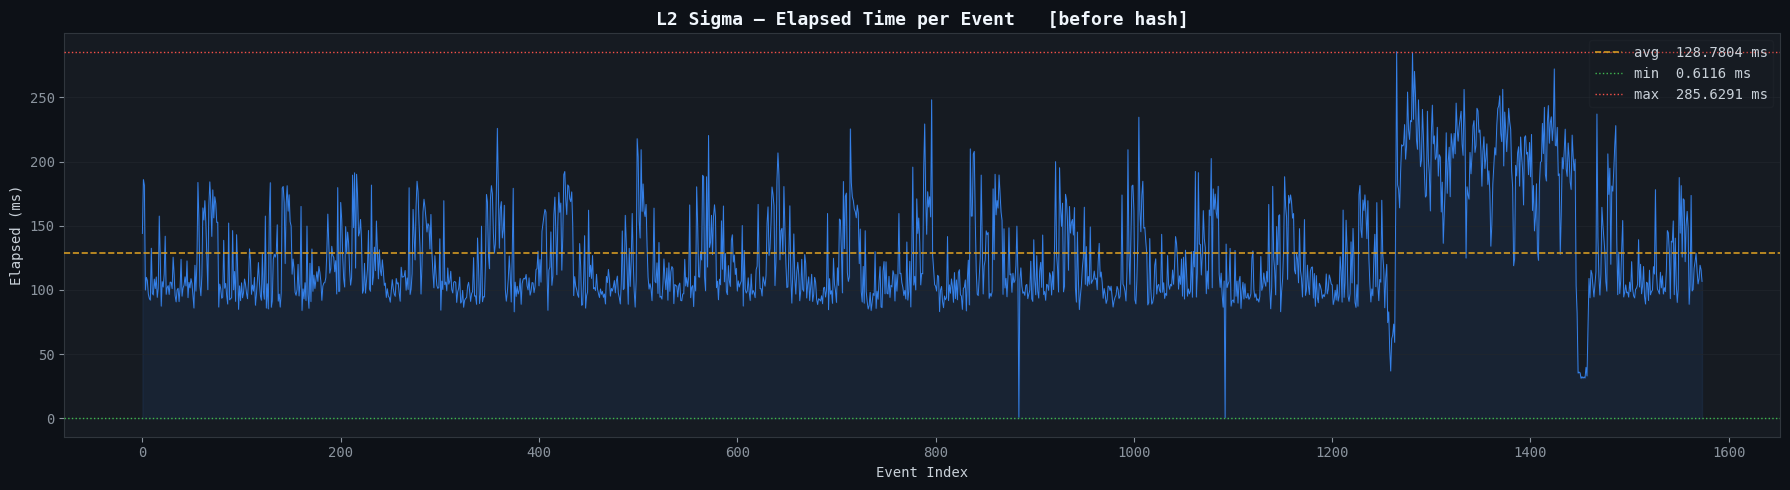

In [12]:
# ── Plot 1 — Raw elapsed time ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(18, 5))

ax.plot(x, elapsed, linewidth=0.7, color=C_FRESH, alpha=0.9, zorder=2)
ax.fill_between(x, elapsed, alpha=0.08, color=C_FRESH)

ax.axhline(summary['l2_avg_time_ms'], color=C_AVG, linestyle='--', linewidth=1.2,
           label=f"avg  {summary['l2_avg_time_ms']} ms", zorder=3)
ax.axhline(summary['l2_min_time_ms'], color=C_MIN, linestyle=':', linewidth=1.0,
           label=f"min  {summary['l2_min_time_ms']} ms", zorder=3)
ax.axhline(summary['l2_max_time_ms'], color=C_MAX, linestyle=':', linewidth=1.0,
           label=f"max  {summary['l2_max_time_ms']} ms", zorder=3)

ax.set_xlabel('Event Index')
ax.set_ylabel('Elapsed (ms)')
ax.set_title(f'L2 Sigma — Elapsed Time per Event   [{label}]')
ax.legend(framealpha=0.2, edgecolor='#30363d')
ax.grid(True, axis='y')
fig.tight_layout()
plt.show()

## Streaming analysis


Timing records: 1574
Parsed events: 1574

QUEUE ANALYSIS

Average service time:
1.403699044472681 sec

Average waiting time:
945.8729230705211 sec

Max waiting time:
1885.961606 sec

P95 waiting time:
1790.3668500999997 sec

Average latency:
947.2766221143582 sec

Max queue size:
1342

THROUGHPUT
Events/sec: 4.8741817010708335
Service rate μ: 0.7124034200476812
Utilization ρ: 6.841884196379355


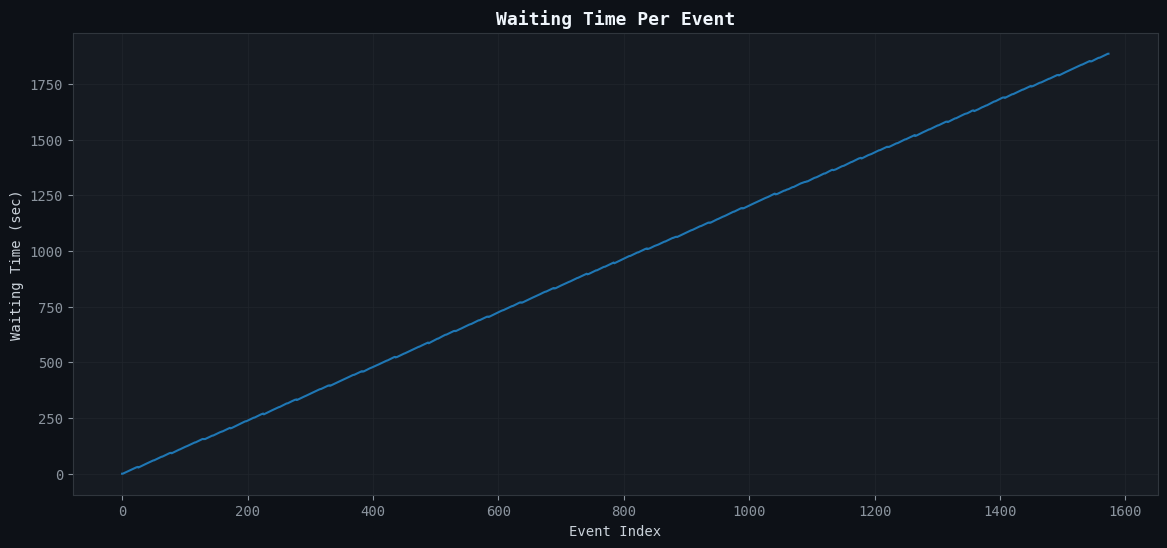

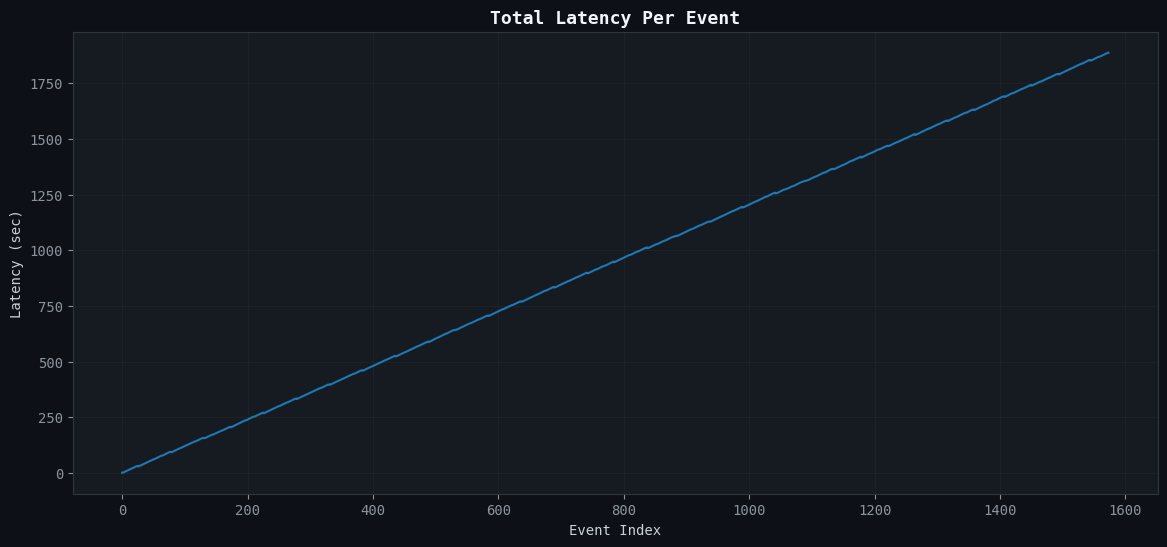

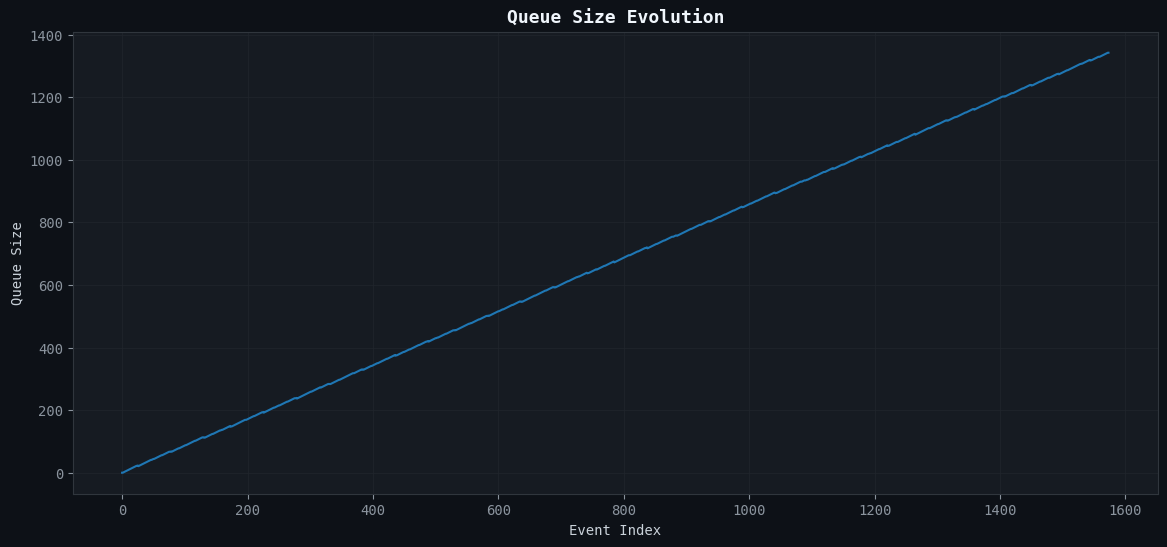

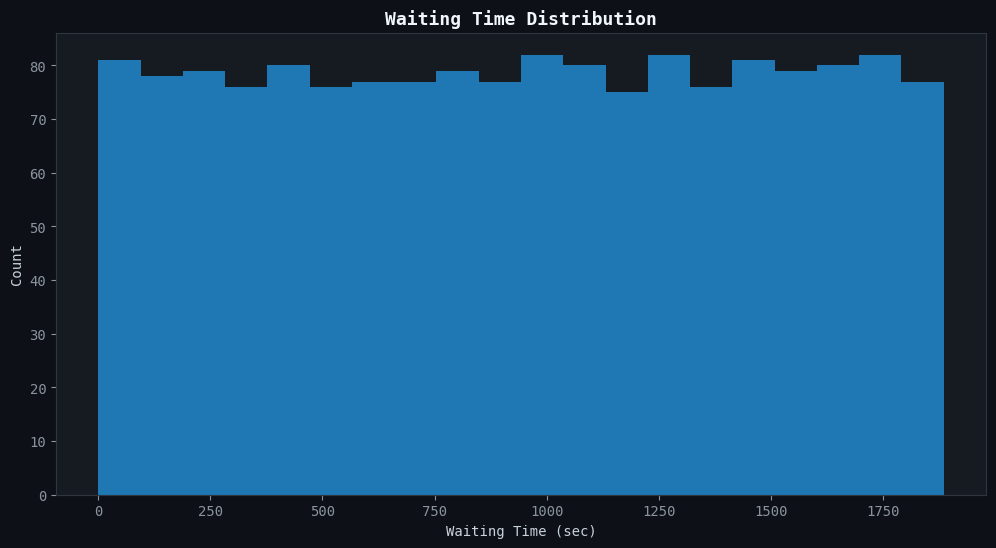

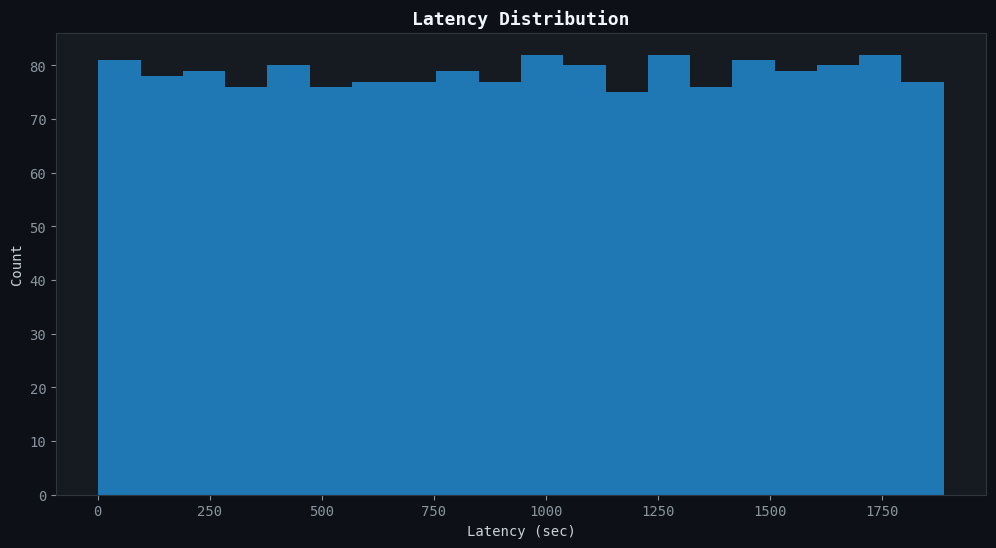

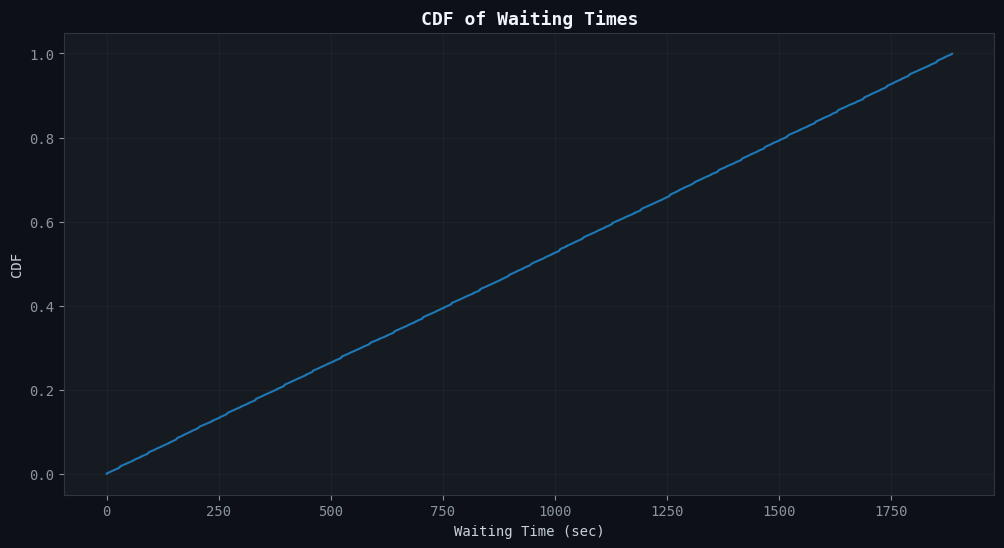

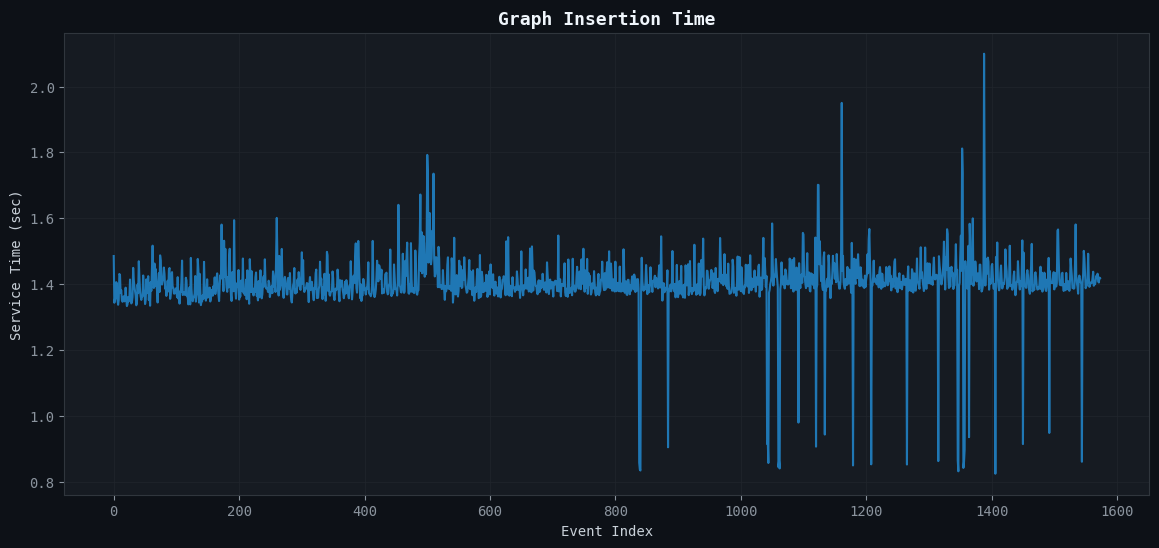


TOP 10 WORST WAITING TIMES
      event_record_id                                              image  \
1573          4658339  C:\Program Files\Docker\cli-plugins\docker-deb...   
1572          4658338  C:\Program Files\Docker\Docker\resources\bin\d...   
1571          4658310  C:\Users\farah\AppData\Local\Programs\Microsof...   
1570          4658337  C:\Program Files\Docker\cli-plugins\docker-ext...   
1569          4658335  C:\Program Files\Docker\cli-plugins\docker-ini...   
1568          4658336  C:\Program Files\Docker\cli-plugins\docker-sbo...   
1567          4658333  C:\Program Files\Docker\cli-plugins\docker-clo...   
1566          4658334  C:\Program Files\Docker\cli-plugins\docker-ai.exe   
1565          4658332  C:\Program Files\Docker\cli-plugins\docker-mod...   
1564          4658331  C:\Program Files\Docker\cli-plugins\docker-deb...   

      waiting_time_sec  latency_sec  queue_size  
1573       1885.961606  1887.379275        1342  
1572       1885.788919  1887.208606

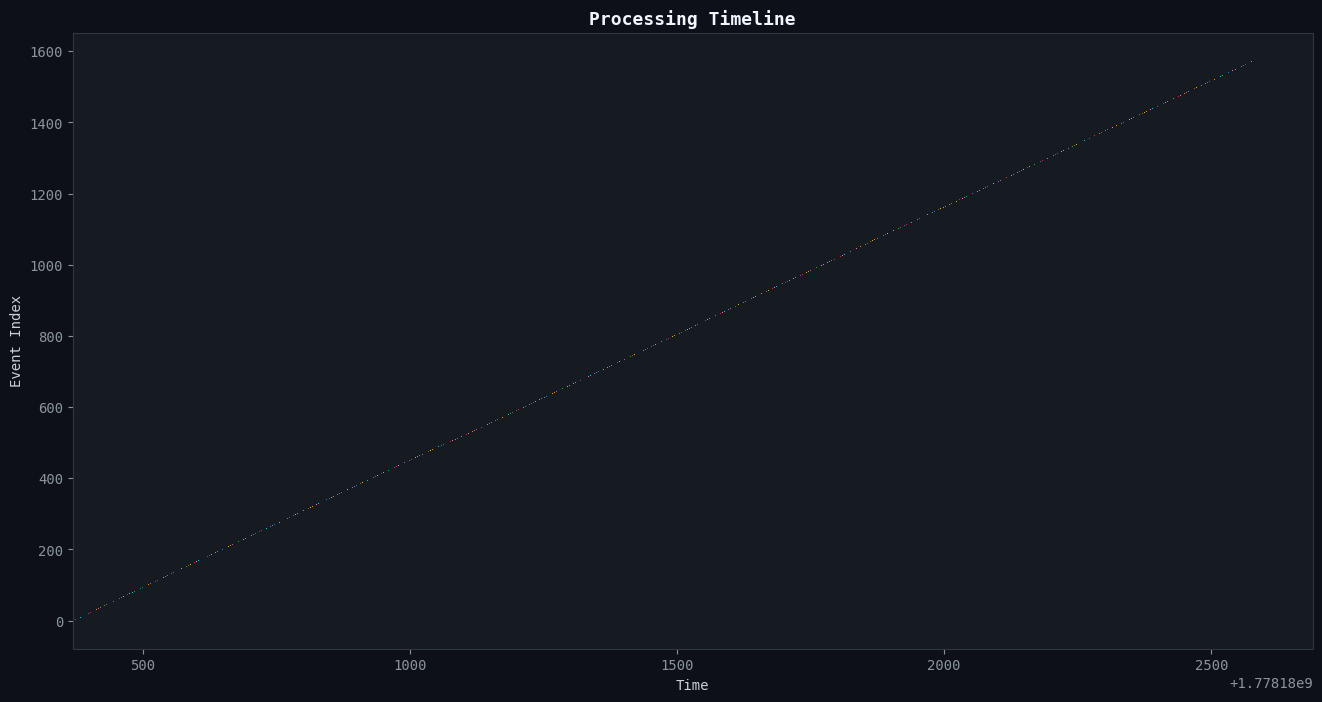


SUMMARY
Total events: 1574
Avg service time: 1.404s
Avg waiting time: 945.873s
Max waiting time: 1885.962s
Avg latency: 947.277s
Max queue size: 1342
System utilization: 6.842


In [ ]:
# ============================================================
# Sysmon Graph Ingestion Queue Analysis
# ============================================================
#
# INPUT:
#   1) events.xml          -> raw Sysmon events
#   2) timings.json        -> graph insertion timings
#
# OUTPUT:
#   - waiting time analysis
#   - latency analysis
#   - queue evolution
#   - throughput
#   - utilization
#   - plots
#
# ============================================================

import json
import xml.etree.ElementTree as ET
from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# CONFIG
# ============================================================

from pathlib import Path

BASE_DIR = Path.cwd().parent

XML_FILE = BASE_DIR / "tests" / "sysmon_events_raw.txt"

TIMING_FILE = Path.cwd() / "graph_timing_streaming.json"

# ============================================================
# LOAD TIMING JSON
# ============================================================

with open(TIMING_FILE, "r", encoding="utf-8") as f:
    timing_data = json.load(f)

records = timing_data["records"]

timing_df = pd.DataFrame(records)

print("Timing records:", len(timing_df))
timing_df.head()

# ============================================================
# PARSE XML EVENTS
# ============================================================

with open(XML_FILE, "r", encoding="utf-8") as f:
    xml_content = f.read()

# split multiple XML events
raw_events = xml_content.split("---")

events = []

namespace = {"ns": "http://schemas.microsoft.com/win/2004/08/events/event"}

for raw_event in raw_events:

    raw_event = raw_event.strip()

    if not raw_event:
        continue

    try:
        root = ET.fromstring(raw_event)

        system = root.find("ns:System", namespace)
        eventdata = root.find("ns:EventData", namespace)

        event_record_id = system.find(
            "ns:EventRecordID", namespace
        ).text

        event_id = system.find(
            "ns:EventID", namespace
        ).text

        computer = system.find(
            "ns:Computer", namespace
        ).text

        fields = {}

        for d in eventdata.findall("ns:Data", namespace):
            name = d.attrib.get("Name")
            value = d.text
            fields[name] = value

        utc_time = fields.get("UtcTime")
        image = fields.get("Image")
        process_guid = fields.get("ProcessGuid")
        parent_guid = fields.get("ParentProcessGuid")
        command_line = fields.get("CommandLine")

        events.append({
            "event_record_id": int(event_record_id),
            "event_id": int(event_id),
            "utc_time": utc_time,
            "image": image,
            "process_guid": process_guid,
            "parent_guid": parent_guid,
            "command_line": command_line,
            "computer": computer
        })

    except Exception as e:
        print("Parse error:", e)

events_df = pd.DataFrame(events)

print("Parsed events:", len(events_df))
events_df.head()

# ============================================================
# PREPARE DATA
# ============================================================

# Convert timestamps
events_df["arrival_time"] = pd.to_datetime(events_df["utc_time"])

# Sort chronologically
events_df = events_df.sort_values("arrival_time").reset_index(drop=True)

# Attach graph_ms
#
# Assumption:
# timings are in same order as events
#
events_df["graph_ms"] = timing_df["graph_ms"].values[:len(events_df)]

# Convert to seconds
events_df["service_time_sec"] = events_df["graph_ms"] / 1000.0

# ============================================================
# QUEUE SIMULATION
# ============================================================

start_times = []
end_times = []
waiting_times = []
latencies = []
queue_lengths = []

previous_end = None

for i, row in events_df.iterrows():

    arrival = row["arrival_time"]
    service = row["service_time_sec"]

    # first event
    if previous_end is None:

        start = arrival

    else:

        start = max(arrival, previous_end)

    end = start + pd.Timedelta(seconds=service)

    waiting = (start - arrival).total_seconds()

    latency = (end - arrival).total_seconds()

    # queue size calculation
    queue_size = 0

    for j in range(i):

        previous_end_j = end_times[j]

        if previous_end_j > arrival:
            queue_size += 1

    start_times.append(start)
    end_times.append(end)
    waiting_times.append(waiting)
    latencies.append(latency)
    queue_lengths.append(queue_size)

    previous_end = end

events_df["start_time"] = start_times
events_df["end_time"] = end_times
events_df["waiting_time_sec"] = waiting_times
events_df["latency_sec"] = latencies
events_df["queue_size"] = queue_lengths

# ============================================================
# BASIC STATS
# ============================================================

print("\n==========================")
print("QUEUE ANALYSIS")
print("==========================")

print("\nAverage service time:")
print(events_df["service_time_sec"].mean(), "sec")

print("\nAverage waiting time:")
print(events_df["waiting_time_sec"].mean(), "sec")

print("\nMax waiting time:")
print(events_df["waiting_time_sec"].max(), "sec")

print("\nP95 waiting time:")
print(events_df["waiting_time_sec"].quantile(0.95), "sec")

print("\nAverage latency:")
print(events_df["latency_sec"].mean(), "sec")

print("\nMax queue size:")
print(events_df["queue_size"].max())

# ============================================================
# ARRIVAL RATE / THROUGHPUT
# ============================================================

duration = (
    events_df["arrival_time"].max()
    - events_df["arrival_time"].min()
).total_seconds()

eps = len(events_df) / duration

avg_service = events_df["service_time_sec"].mean()

mu = 1 / avg_service

rho = eps / mu

print("\n==========================")
print("THROUGHPUT")
print("==========================")

print("Events/sec:", eps)

print("Service rate μ:", mu)

print("Utilization ρ:", rho)

# ============================================================
# PLOT 1 — WAITING TIME
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    events_df.index,
    events_df["waiting_time_sec"],
)

plt.title("Waiting Time Per Event")
plt.xlabel("Event Index")
plt.ylabel("Waiting Time (sec)")
plt.grid(True)

plt.show()

# ============================================================
# PLOT 2 — LATENCY
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    events_df.index,
    events_df["latency_sec"],
)

plt.title("Total Latency Per Event")
plt.xlabel("Event Index")
plt.ylabel("Latency (sec)")
plt.grid(True)

plt.show()

# ============================================================
# PLOT 3 — QUEUE SIZE
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    events_df.index,
    events_df["queue_size"],
)

plt.title("Queue Size Evolution")
plt.xlabel("Event Index")
plt.ylabel("Queue Size")
plt.grid(True)

plt.show()

# ============================================================
# PLOT 4 — HISTOGRAM WAITING TIMES
# ============================================================

plt.figure(figsize=(12, 6))

plt.hist(
    events_df["waiting_time_sec"],
    bins=20,
)

plt.title("Waiting Time Distribution")
plt.xlabel("Waiting Time (sec)")
plt.ylabel("Count")

plt.show()

# ============================================================
# PLOT 5 — HISTOGRAM LATENCY
# ============================================================

plt.figure(figsize=(12, 6))

plt.hist(
    events_df["latency_sec"],
    bins=20,
)

plt.title("Latency Distribution")
plt.xlabel("Latency (sec)")
plt.ylabel("Count")

plt.show()

# ============================================================
# PLOT 6 — CDF WAITING TIMES
# ============================================================

sorted_wait = np.sort(events_df["waiting_time_sec"])
cdf = np.arange(len(sorted_wait)) / len(sorted_wait)

plt.figure(figsize=(12, 6))

plt.plot(sorted_wait, cdf)

plt.title("CDF of Waiting Times")
plt.xlabel("Waiting Time (sec)")
plt.ylabel("CDF")

plt.grid(True)

plt.show()

# ============================================================
# PLOT 7 — SERVICE TIME
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    events_df.index,
    events_df["service_time_sec"],
)

plt.title("Graph Insertion Time")
plt.xlabel("Event Index")
plt.ylabel("Service Time (sec)")

plt.grid(True)

plt.show()

# ============================================================
# TOP WORST EVENTS
# ============================================================

worst = events_df.sort_values(
    "waiting_time_sec",
    ascending=False
).head(10)

print("\n==========================")
print("TOP 10 WORST WAITING TIMES")
print("==========================")

display_cols = [
    "event_record_id",
    "image",
    "waiting_time_sec",
    "latency_sec",
    "queue_size"
]

print(worst[display_cols])

# ============================================================
# OPTIONAL EXPORT
# ============================================================

events_df.to_csv("queue_analysis.csv", index=False)

print("\nSaved: queue_analysis.csv")

# ============================================================
# OPTIONAL GANTT-LIKE TIMELINE
# ============================================================

plt.figure(figsize=(16, 8))

for i, row in events_df.iterrows():

    start = row["start_time"]
    end = row["end_time"]

    duration = (end - start).total_seconds()

    plt.barh(
        y=i,
        width=duration,
        left=start.timestamp(),
    )

plt.title("Processing Timeline")
plt.xlabel("Time")
plt.ylabel("Event Index")

plt.show()

# ============================================================
# SUMMARY
# ============================================================

print("\n==========================")
print("SUMMARY")
print("==========================")

print(f"Total events: {len(events_df)}")

print(f"Avg service time: {avg_service:.3f}s")

print(f"Avg waiting time: {events_df['waiting_time_sec'].mean():.3f}s")

print(f"Max waiting time: {events_df['waiting_time_sec'].max():.3f}s")

print(f"Avg latency: {events_df['latency_sec'].mean():.3f}s")

print(f"Max queue size: {events_df['queue_size'].max()}")

print(f"System utilization: {rho:.3f}")

1. System Model
The graph ingestion component is modeled as an M/G/1 queue:

Arrivals — Sysmon events generated by the monitored host, arriving at rate λ

Server — single Memgraph writer executing one Cypher transaction per event

Service time — wall-clock time to complete one process_event() call


2. Workload Characterization
The dataset contains 1,574 Sysmon events captured from an endpoint. Event timestamps span a continuous 
monitoring window, giving a natural arrival process.

MetricValueTotal events 1,574 
Capture duration ~323 seconds 
Arrival rate λ 4.87 events/sec 
Avg service time (1/μ)1.403 sec/event
Service rate μ 0.712 events/sec
The service time of 1.403s reflects the cost of the original single-event path: for each event, GraphBuilder issues 4–8 sequential Cypher round-trips to Memgraph (template upsert, instance merge, artifact merge, edge merge), each incurring individual network + transaction overhead.

3. Stability Analysis
System utilization ρ is defined as:
ρ = λ / μ = arrival_rate × avg_service_time
ρ = 4.87 × 1.403 = 6.84
A single-server queue is stable only when ρ < 1. At ρ = 6.84 the system is 6.84× over capacity. The queue grows at a net rate of:
λ - μ = 4.87 - 0.71 = 4.16 events/sec accumulating indefinitely
This explains the simulation results:
Queue MetricValueAvg waiting time 945.87 sec
Max waiting time 1,885.96 sec
P95 waiting time1,790.37 sec
Avg latency 947.28 sec
Maxqueue size 1,342 events
By the time the last event was processed, 1,342 events were waiting — 85% of the entire dataset was backlogged simultaneously. An average event waited over 15 minutes before being written to the graph, making real-time threat detection impossible.

4. Root Cause
The bottleneck is not Memgraph itself but the per-event round-trip pattern. Each event triggers multiple independent execute() calls:
handle_event_1  →  8 round-trips  (2 templates + 2 instances +
                                   INSTANCE_OF + RAN_AS + CHILD_OF + edge)
handle_event_3  →  4 round-trips  (template + instance + Network + edge)
handle_event_11 →  4 round-trips  (template + instance + File + edge)
At 1,574 events this produces roughly 6,000–12,000 individual Cypher transactions, each with its own TCP round-trip, server parse, and commit overhead. The fixed overhead per transaction dominates the total cost.

## Batch processing ( 2s )

BATCH TIMING FILE LOADED
  Total records      : 1574
  Batch graph        : True
  Configured size    : 100
  Configured timeout : 2.0s
  Avg graph_ms       : 156.3288 ms/event

  Total flushes      : 99
  Total events       : 52296 (sum of batch sizes)

SECTION 1 — BATCH SIZE DISTRIBUTION

  Min batch size  : 1
  Max batch size  : 53
  Avg batch size  : 15.90
  Median          : 2

  Size-triggered flushes    : 0  (batch_size=100 reached)
  Timeout-triggered flushes : 99  (timeout=2.0s fired first)


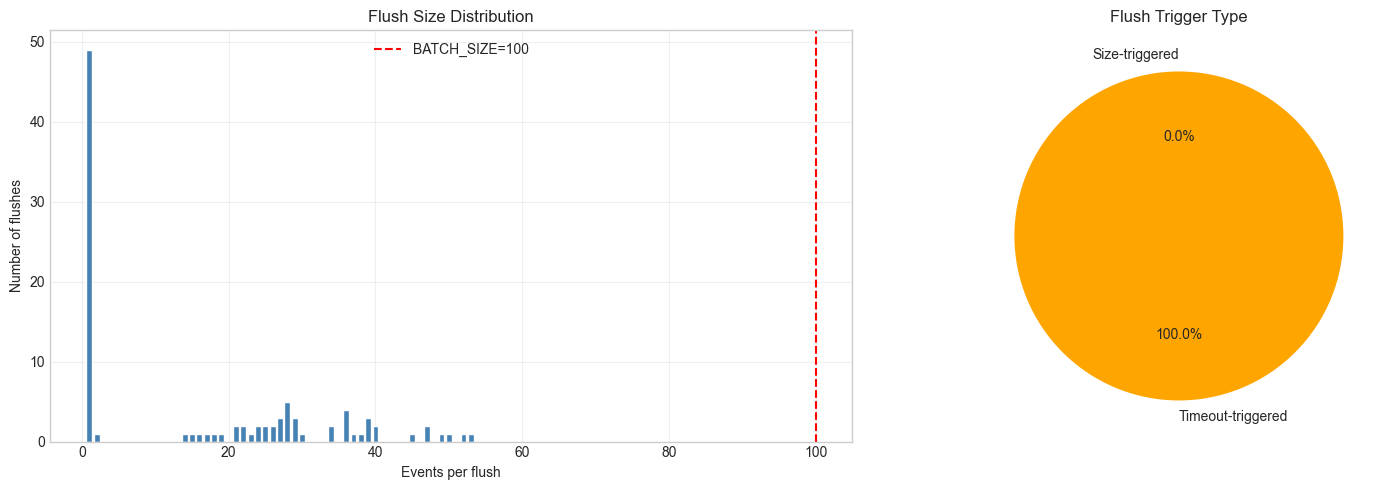

In [48]:
# ============================================================
# Batch vs Streaming — Graph Ingestion Analysis
# ============================================================
#
# INPUT:
#   1) batch timing JSON    → produced by agent.py with BATCH_GRAPH=True
#   2) streaming stats      → hardcoded from your previous run
#
# OUTPUT:
#   - batch size distribution
#   - amortised cost per event
#   - flush cost distribution
#   - queue simulation (batch-aware)
#   - before/after comparison table
#   - utilization ρ comparison
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict

# ============================================================
# CONFIG
# ============================================================

BATCH_TIMING_FILE = Path.cwd() / "graph_timing_20260508_114937.json"

# Streaming baseline (from your first run — hardcoded)
STREAMING = {
    "avg_service_ms":  1403.699,
    "avg_wait_sec":    945.873,
    "max_wait_sec":    1885.962,
    "p95_wait_sec":    1790.367,
    "avg_latency_sec": 947.277,
    "max_queue_size":  1342,
    "total_events":    1574,
    "eps":             4.8742,
    "rho":             6.8419,
}

# ============================================================
# LOAD BATCH TIMING
# ============================================================

with open(BATCH_TIMING_FILE, "r", encoding="utf-8") as f:
    timing_data = json.load(f)

records  = timing_data["records"]
summary  = timing_data.get("summary", {})

timing_df = pd.DataFrame(records)

print("=" * 60)
print("BATCH TIMING FILE LOADED")
print("=" * 60)
print(f"  Total records      : {len(timing_df)}")
print(f"  Batch graph        : {summary.get('batch_graph')}")
print(f"  Configured size    : {summary.get('batch_size')}")
print(f"  Configured timeout : {summary.get('batch_timeout')}s")
print(f"  Avg graph_ms       : {summary.get('avg_graph_ms')} ms/event")

# ============================================================
# DEDUPLICATE: one row per flush (not one row per event)
# ============================================================

# Each flush appears N times (once per event in the batch).
# Deduplicate on batch_total_ms to get one row per actual flush.
flushes_df = (
    timing_df
    .drop_duplicates(subset=["batch_total_ms"])
    .reset_index(drop=True)
)

print(f"\n  Total flushes      : {len(flushes_df)}")
print(f"  Total events       : {timing_df['batch_size'].sum()} "
      f"(sum of batch sizes)")

# ============================================================
# SECTION 1 — BATCH SIZE DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("SECTION 1 — BATCH SIZE DISTRIBUTION")
print("=" * 60)

size_counts = flushes_df["batch_size"].value_counts().sort_index()

print(f"\n  Min batch size  : {flushes_df['batch_size'].min()}")
print(f"  Max batch size  : {flushes_df['batch_size'].max()}")
print(f"  Avg batch size  : {flushes_df['batch_size'].mean():.2f}")
print(f"  Median          : {flushes_df['batch_size'].median():.0f}")

timeout_flushes = (flushes_df["batch_size"] < summary.get("batch_size", 50)).sum()
size_flushes    = (flushes_df["batch_size"] >= summary.get("batch_size", 50)).sum()

print(f"\n  Size-triggered flushes    : {size_flushes}  "
      f"(batch_size={summary.get('batch_size', 50)} reached)")
print(f"  Timeout-triggered flushes : {timeout_flushes}  "
      f"(timeout={summary.get('batch_timeout', 2.0)}s fired first)")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(size_counts.index, size_counts.values, color="steelblue",
            edgecolor="white")
axes[0].axvline(x=summary.get("batch_size", 50), color="red",
                linestyle="--", label=f"BATCH_SIZE={summary.get('batch_size',50)}")
axes[0].set_title("Flush Size Distribution")
axes[0].set_xlabel("Events per flush")
axes[0].set_ylabel("Number of flushes")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].pie(
    [size_flushes, timeout_flushes],
    labels=["Size-triggered", "Timeout-triggered"],
    colors=["steelblue", "orange"],
    autopct="%1.1f%%",
    startangle=90,
)
axes[1].set_title("Flush Trigger Type")

plt.tight_layout()
plt.savefig("batch_size_distribution.png", dpi=150, bbox_inches="tight")
plt.show()



## Timeout=2s

Total events: 1574
Valid events: 1574

================ SLA METRICS ================
Avg waiting time: 1.4194257400238832
Max waiting time: 5.465112686157227
P95 waiting time: 4.48856703042984

Avg processing time (graph): 0.15651217585768634

Avg total latency: 1.5759379158815696
Max latency: 5.587104401712794
P95 latency: 4.6173396374454345

Throughput: 4.820885654078714 events/sec

================ SLA ANALYSIS ================
SLA threshold: 2.0 sec
Violation rate: 24.7141041931385 %


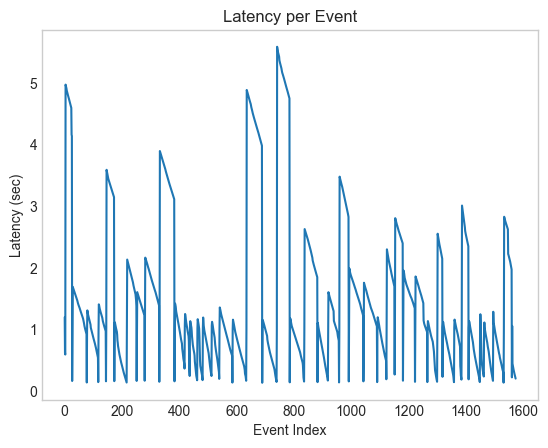

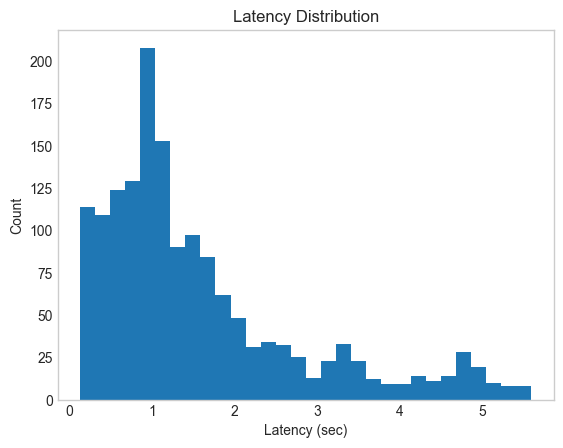

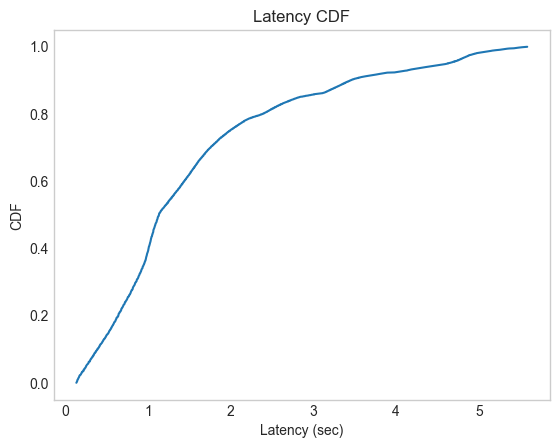


================ SUMMARY ================
Avg latency: 1.5759s
P95 latency: 4.6173s
SLA violation rate: 0.2471


In [50]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LOAD DATA
# ============================================================

FILE = "graph_timing_batch_2s.json"

with open(FILE, "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data["records"])

print("Total events:", len(df))

# ============================================================
# CORE METRICS (CLEAN MODEL)
# ============================================================

df["arrival_time"] = df["arrival_time"].astype(float)
df["flush_time"] = df["flush_time"].astype(float)

# latency from batching side
df["waiting_time_sec"] = df["flush_time"] - df["arrival_time"]

# processing time from graph
df["processing_sec"] = df["graph_ms"] / 1000.0

# total latency (REAL SLA METRIC)
df["latency_sec"] = df["waiting_time_sec"] + df["processing_sec"]

# ============================================================
# CLEAN INVALID VALUES
# ============================================================

df = df[
    (df["waiting_time_sec"] >= 0) &
    (df["processing_sec"] >= 0) &
    (df["latency_sec"] >= 0)
]

print("Valid events:", len(df))

# ============================================================
# STATISTICS
# ============================================================

print("\n================ SLA METRICS ================")

print("Avg waiting time:", df["waiting_time_sec"].mean())
print("Max waiting time:", df["waiting_time_sec"].max())
print("P95 waiting time:", df["waiting_time_sec"].quantile(0.95))

print("\nAvg processing time (graph):", df["processing_sec"].mean())

print("\nAvg total latency:", df["latency_sec"].mean())
print("Max latency:", df["latency_sec"].max())
print("P95 latency:", df["latency_sec"].quantile(0.95))

# ============================================================
# UTILIZATION INSIGHT
# ============================================================

duration = df["arrival_time"].max() - df["arrival_time"].min()
eps = len(df) / duration if duration > 0 else 0

print("\nThroughput:", eps, "events/sec")

# ============================================================
# SLA BREACH ANALYSIS (2 sec threshold)
# ============================================================

SLA = 2.0

df["sla_violation"] = df["latency_sec"] > SLA

violation_rate = df["sla_violation"].mean()

print("\n================ SLA ANALYSIS ================")
print("SLA threshold:", SLA, "sec")
print("Violation rate:", violation_rate * 100, "%")

# ============================================================
# VISUALS
# ============================================================

plt.figure()
plt.plot(df["latency_sec"].values)
plt.title("Latency per Event")
plt.xlabel("Event Index")
plt.ylabel("Latency (sec)")
plt.grid()
plt.show()

plt.figure()
plt.hist(df["latency_sec"], bins=30)
plt.title("Latency Distribution")
plt.xlabel("Latency (sec)")
plt.ylabel("Count")
plt.grid()
plt.show()

sorted_lat = np.sort(df["latency_sec"])
cdf = np.arange(len(sorted_lat)) / len(sorted_lat)

plt.figure()
plt.plot(sorted_lat, cdf)
plt.title("Latency CDF")
plt.xlabel("Latency (sec)")
plt.ylabel("CDF")
plt.grid()
plt.show()

# ============================================================
# SUMMARY
# ============================================================

print("\n================ SUMMARY ================")
print(f"Avg latency: {df['latency_sec'].mean():.4f}s")
print(f"P95 latency: {df['latency_sec'].quantile(0.95):.4f}s")
print(f"SLA violation rate: {violation_rate:.4f}")

In [51]:
# ============================================================
# UTILIZATION (ρ) - CORRECT QUEUE MODEL
# ============================================================

# sort by time (IMPORTANT)
df = df.sort_values("arrival_time")

# inter-arrival times
df["inter_arrival"] = df["arrival_time"].diff()

# λ (arrival rate)
mean_inter_arrival = df["inter_arrival"].mean()
lambda_rate = 1 / mean_inter_arrival if mean_inter_arrival > 0 else 0

# service time (graph execution only)
df["service_time"] = df["graph_ms"] / 1000.0
mu = 1 / df["service_time"].mean() if df["service_time"].mean() > 0 else 0

# utilization
rho = lambda_rate / mu if mu > 0 else 0

print("\n================ UTILIZATION =================")
print("Arrival rate λ:", lambda_rate)
print("Service rate μ:", mu)
print("Utilization ρ:", rho)


================ UTILIZATION =================
Arrival rate λ: 4.817822829647914
Service rate μ: 6.3892792654629105
Utilization ρ: 0.7540479339650303



================ KNEE DETECTION ================
Knee index: 1178
Knee latency value: 1.9764 sec


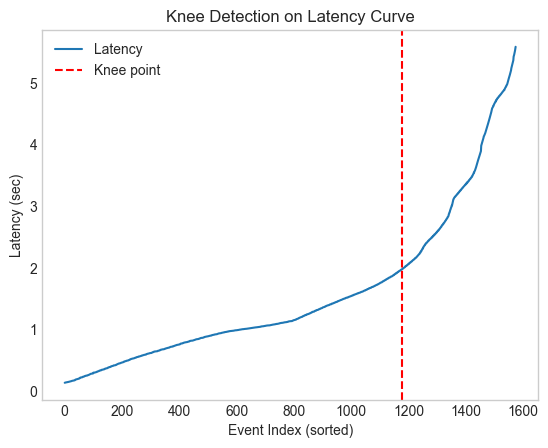

In [52]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# KNEE DETECTION ON LATENCY CURVE
# ============================================================

lat = np.sort(df["latency_sec"].values)

x = np.arange(len(lat))
y = lat

# normalize (important for stable knee detection)
x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (y - y.min()) / (y.max() - y.min())

# line between first and last point
p1 = np.array([x_norm[0], y_norm[0]])
p2 = np.array([x_norm[-1], y_norm[-1]])

line_vec = p2 - p1
line_vec = line_vec / np.linalg.norm(line_vec)

# compute distance of each point to line
distances = []

for i in range(len(x_norm)):
    point = np.array([x_norm[i], y_norm[i]])
    vec = point - p1

    proj = np.dot(vec, line_vec) * line_vec
    perp = vec - proj

    dist = np.linalg.norm(perp)
    distances.append(dist)

distances = np.array(distances)

# knee index = max distance
knee_index = np.argmax(distances)

knee_value = lat[knee_index]

print("\n================ KNEE DETECTION ================")
print(f"Knee index: {knee_index}")
print(f"Knee latency value: {knee_value:.4f} sec")
plt.figure()

plt.plot(lat, label="Latency")
plt.axvline(knee_index, color="red", linestyle="--", label="Knee point")

plt.title("Knee Detection on Latency Curve")
plt.xlabel("Event Index (sorted)")
plt.ylabel("Latency (sec)")
plt.legend()
plt.grid()

plt.show()

# Timeout = 1.5s

Total events: 1574
Valid events: 1574

================ BATCH METRICS ================
Avg waiting time: 0.24794284830856808
P95 waiting time: 0.49133459329605095
Max waiting time: 0.64906907081604

Avg processing time: 0.19871293900888942

Avg latency: 0.44665578731745753
P95 latency: 0.8488827348234462
Max latency: 1.3994224320886133

================ SLA (1.5s) ================
Violation rate: 0.0 %

================ UTILIZATION ================
Events/sec (λ): 4.45568166043945
Service rate μ: 5.0323849316891485
Utilization ρ: 0.8854015980339317

================ COMPARISON ================
Streaming avg latency: 947.277
Batch avg latency: 0.44665578731745753
Streaming waiting: 945.873
Batch waiting: 0.24794284830856808
Speedup (compute): 7.063953696227126 x


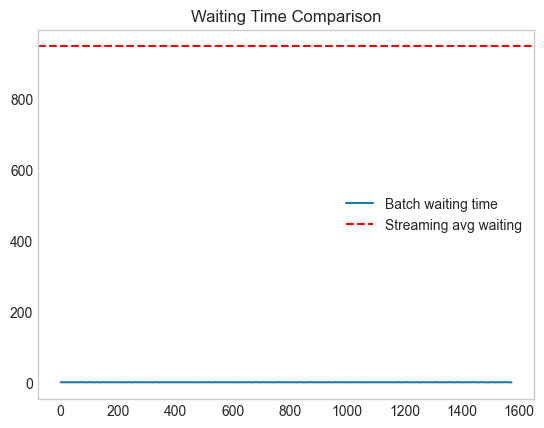

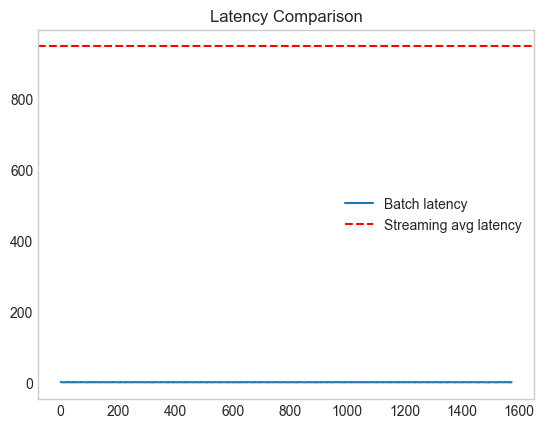

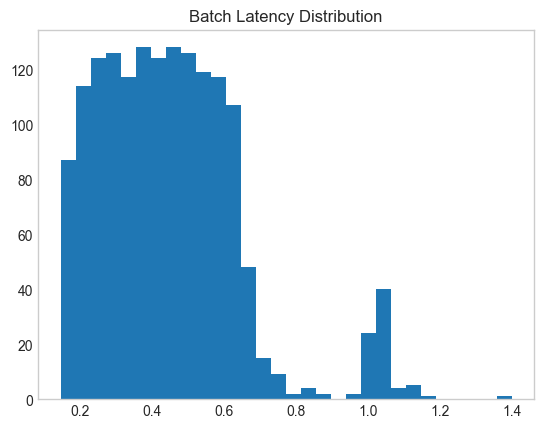


================ SUMMARY ================
Avg waiting time: 0.2479s
P95 waiting time: 0.4913s
Avg latency: 0.4467s
P95 latency: 0.8489s
SLA violation rate: 0.0000
Utilization ρ: 0.8854
Speedup vs streaming: 7.06x


In [56]:
# ============================================================
# Batch vs Streaming — Graph Ingestion Analysis (CLEAN MODEL)
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CONFIG
# ============================================================



STREAMING = {
    "avg_service_ms": 1403.699,
    "avg_wait_sec": 945.873,
    "avg_latency_sec": 947.277,
    "eps": 4.8742,
    "rho": 6.8419,
}

SLA = 1.5  # seconds

# ============================================================
# LOAD DATA
# ============================================================
FILE="graph_timing_batch_1s.json"
with open(FILE, "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data["records"])

print("Total events:", len(df))

# ============================================================
# CORE METRICS (CORRECTED MODEL)
# ============================================================

df["arrival_time"] = df["arrival_time"].astype(float)
df["flush_time"] = df["flush_time"].astype(float)

# 1. WAITING TIME (batch delay)
df["waiting_time_sec"] = df["flush_time"] - df["arrival_time"]

# 2. PROCESSING TIME (graph execution)
df["processing_sec"] = df["graph_ms"] / 1000.0

# 3. TOTAL LATENCY
df["latency_sec"] = df["waiting_time_sec"] + df["processing_sec"]

# ============================================================
# CLEAN INVALID DATA
# ============================================================

df = df[
    (df["waiting_time_sec"] >= 0) &
    (df["processing_sec"] >= 0) &
    (df["latency_sec"] >= 0)
]

print("Valid events:", len(df))

# ============================================================
# BASIC STATISTICS
# ============================================================

print("\n================ BATCH METRICS ================")

print("Avg waiting time:", df["waiting_time_sec"].mean())
print("P95 waiting time:", df["waiting_time_sec"].quantile(0.95))
print("Max waiting time:", df["waiting_time_sec"].max())

print("\nAvg processing time:", df["processing_sec"].mean())

print("\nAvg latency:", df["latency_sec"].mean())
print("P95 latency:", df["latency_sec"].quantile(0.95))
print("Max latency:", df["latency_sec"].max())

# ============================================================
# SLA ANALYSIS
# ============================================================

df["sla_violation"] = df["latency_sec"] > SLA
violation_rate = df["sla_violation"].mean()

print("\n================ SLA (1.5s) ================")
print("Violation rate:", round(violation_rate * 100, 2), "%")

# ============================================================
# UTILIZATION ρ (CORRECT)
# ============================================================

eps = len(df) / (df["arrival_time"].max() - df["arrival_time"].min())
mu = 1 / df["processing_sec"].mean()
rho = eps / mu

print("\n================ UTILIZATION ================")
print("Events/sec (λ):", eps)
print("Service rate μ:", mu)
print("Utilization ρ:", rho)

# ============================================================
# STREAMING COMPARISON
# ============================================================

speedup = STREAMING["avg_service_ms"] / (df["processing_sec"].mean() * 1000)

print("\n================ COMPARISON ================")
print("Streaming avg latency:", STREAMING["avg_latency_sec"])
print("Batch avg latency:", df["latency_sec"].mean())

print("Streaming waiting:", STREAMING["avg_wait_sec"])
print("Batch waiting:", df["waiting_time_sec"].mean())

print("Speedup (compute):", speedup, "x")

# ============================================================
# VISUALS
# ============================================================

plt.figure()
plt.plot(df["waiting_time_sec"].values, label="Batch waiting time")
plt.axhline(STREAMING["avg_wait_sec"], color="red", linestyle="--",
            label="Streaming avg waiting")
plt.title("Waiting Time Comparison")
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.plot(df["latency_sec"].values, label="Batch latency")
plt.axhline(STREAMING["avg_latency_sec"], color="red", linestyle="--",
            label="Streaming avg latency")
plt.title("Latency Comparison")
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.hist(df["latency_sec"], bins=30)
plt.title("Batch Latency Distribution")
plt.grid()
plt.show()

# ============================================================
# SUMMARY
# ============================================================

print("\n================ SUMMARY ================")

print(f"Avg waiting time: {df['waiting_time_sec'].mean():.4f}s")
print(f"P95 waiting time: {df['waiting_time_sec'].quantile(0.95):.4f}s")

print(f"Avg latency: {df['latency_sec'].mean():.4f}s")
print(f"P95 latency: {df['latency_sec'].quantile(0.95):.4f}s")

print(f"SLA violation rate: {violation_rate:.4f}")
print(f"Utilization ρ: {rho:.4f}")
print(f"Speedup vs streaming: {speedup:.2f}x")

BATCH TIMING FILE LOADED
Total records: 1574

================ SECTION 1 =================
Flush Size Distribution
Min batch size: 1
Max batch size: 32
Avg batch size: 20.48


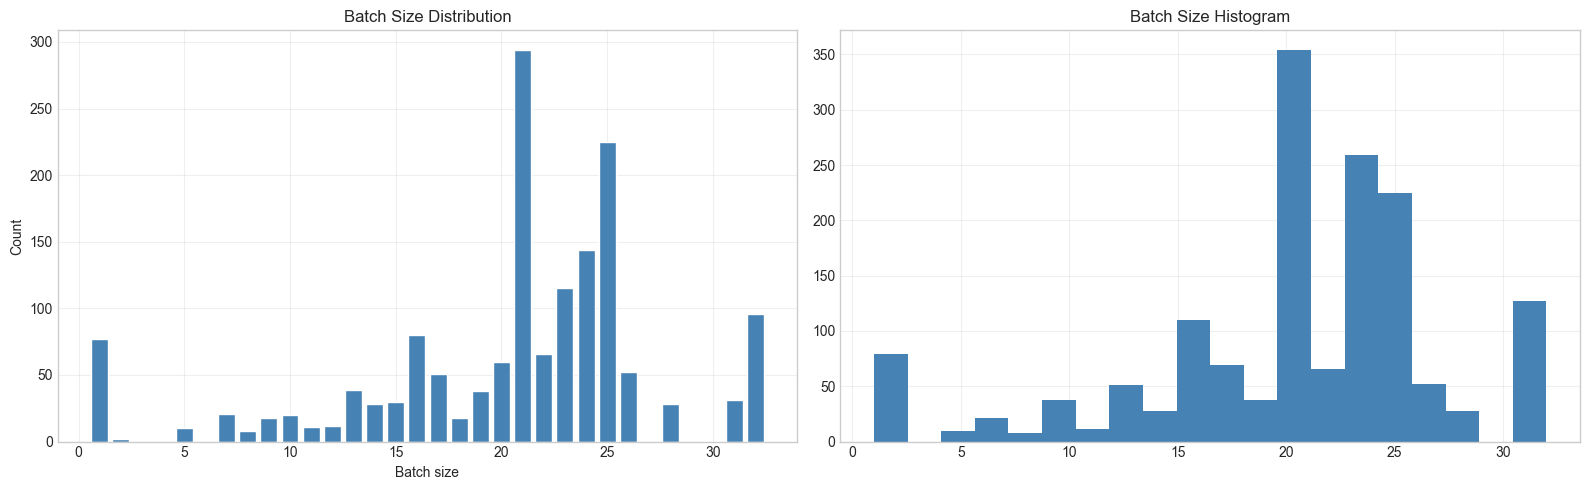


================ SECTION 2 =================
Avg cost: 198.71 ms/event
P95 cost: 388.74 ms/event
Ceiling: 205.16 ms/event
Speedup vs streaming: 7.06x


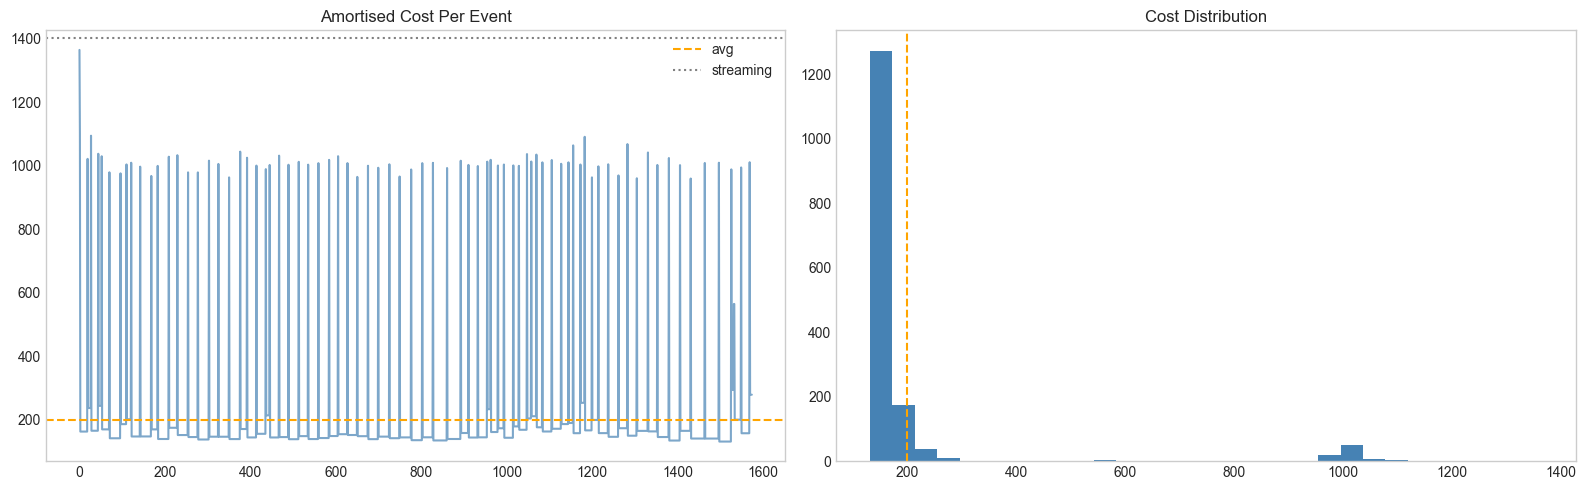


================ SECTION 3 =================
Avg flush cost: 2017.90 ms
P95 flush cost: 3705.93 ms


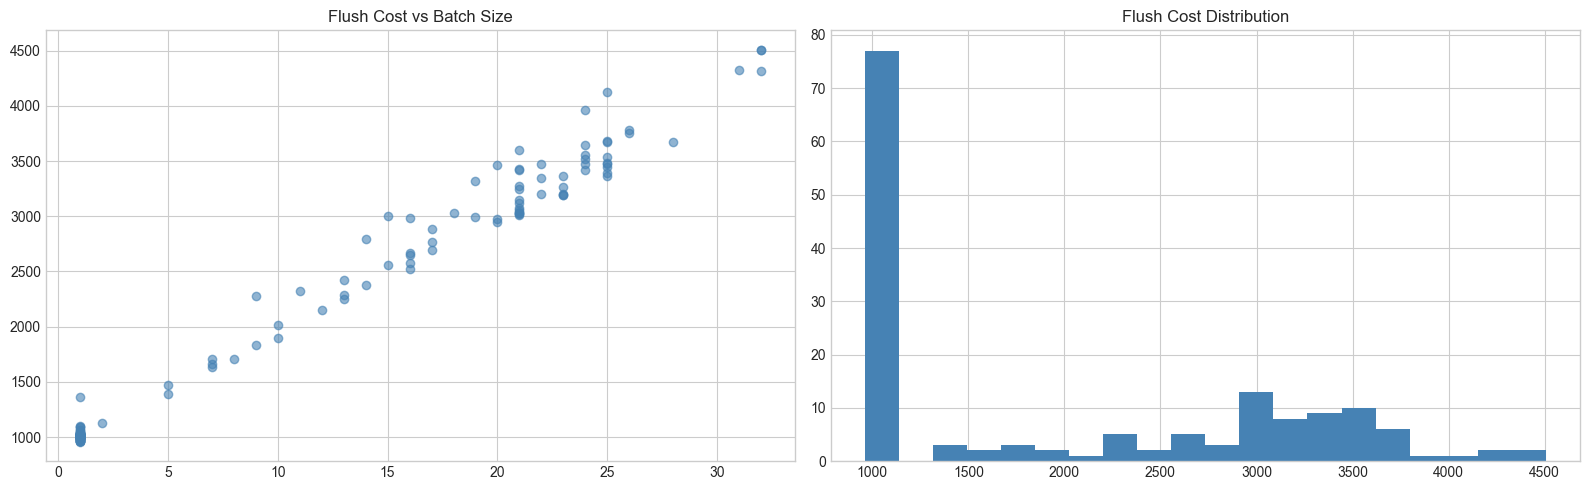


================ COMPARISON =================
Streaming wait: 945.87s
Batch wait:     0.2479s
Streaming latency: 947.28s
Batch latency:     0.4467s
Utilization ρ: 0.8854
SLA violation: 0.0000%

================ TAIL =================
P95 latency: 0.8489s
P99 latency: 1.0498s


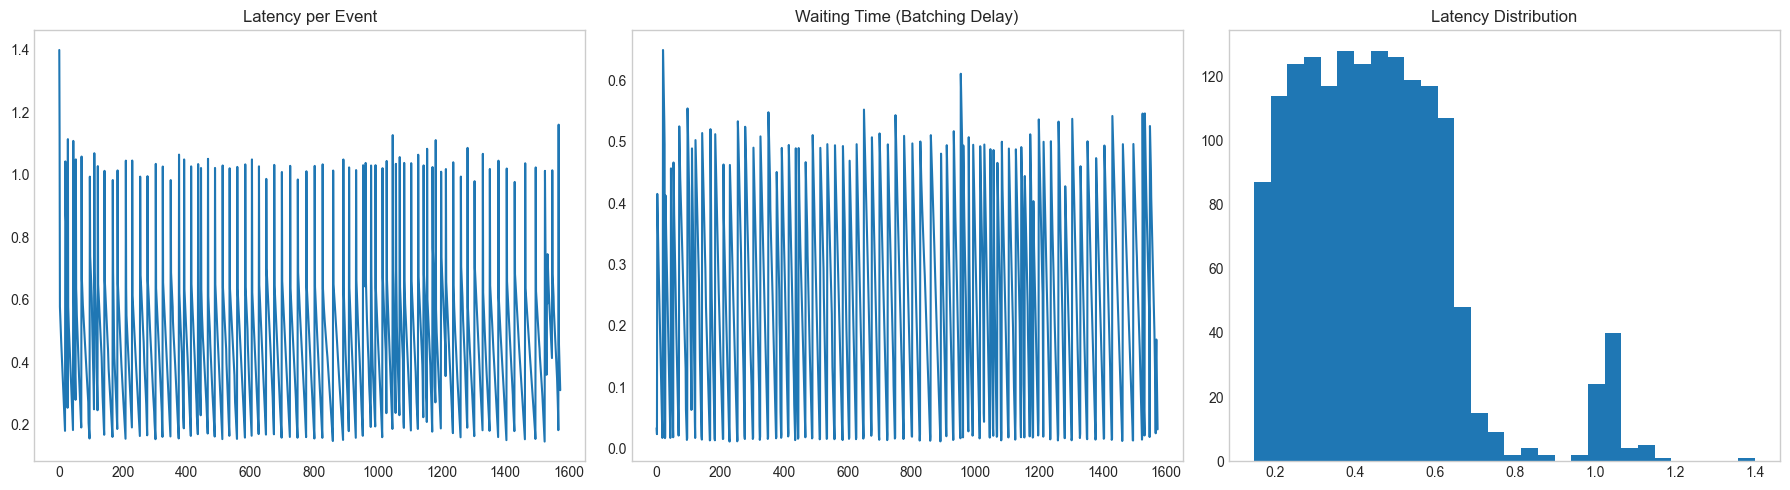


================ SUMMARY =================
Avg latency: 0.4467s
Avg wait:    0.2479s
P95 latency: 0.8489s
ρ: 0.8854
SLA violations: 0.0000%


In [54]:
# ============================================================
# Batch vs Streaming — Graph Ingestion Analysis (REAL FIELDS)
# ============================================================



STREAMING = {
    "avg_service_ms": 1403.699,
    "avg_wait_sec": 945.873,
    "avg_latency_sec": 947.277,
    "p95_wait_sec": 1790.367,
    "rho": 6.8419,
    "eps": 4.8742,
}

# ============================================================
# LOAD DATA
# ============================================================

with open(FILE, "r") as f:
    data = json.load(f)

df = pd.DataFrame(data["records"])

print("=" * 60)
print("BATCH TIMING FILE LOADED")
print("=" * 60)
print(f"Total records: {len(df)}")

# ============================================================
# CORE METRICS (ONLY YOUR FIELDS)
# ============================================================

df["arrival_time"] = df["arrival_time"].astype(float)
df["flush_time"] = df["flush_time"].astype(float)

# WAITING TIME (already meaningful but we recompute safely)
df["wait_sec"] = df["flush_time"] - df["arrival_time"]

# PROCESSING TIME
df["proc_sec"] = df["graph_ms"] / 1000.0

# TOTAL LATENCY
df["latency_sec"] = df["wait_sec"] + df["proc_sec"]

# ============================================================
# UTILIZATION (CORRECT MODEL)
# ============================================================

duration = df["arrival_time"].max() - df["arrival_time"].min()
eps = len(df) / duration

mu = 1 / df["proc_sec"].mean()
rho = eps / mu

# ============================================================
# SLA ANALYSIS (optional but useful)
# ============================================================

SLA = 2.0
df["sla_violation"] = df["latency_sec"] > SLA
violation_rate = df["sla_violation"].mean()

# ============================================================
# SECTION 1 — "FLUSH SIZE" DISTRIBUTION (FROM REAL DATA)
# ============================================================

print("\n================ SECTION 1 =================")
print("Flush Size Distribution")

size_counts = df["batch_size"].value_counts().sort_index()

print(f"Min batch size: {df['batch_size'].min()}")
print(f"Max batch size: {df['batch_size'].max()}")
print(f"Avg batch size: {df['batch_size'].mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(size_counts.index, size_counts.values,
            color="steelblue", edgecolor="white")
axes[0].set_title("Batch Size Distribution")
axes[0].set_xlabel("Batch size")
axes[0].set_ylabel("Count")
axes[0].grid(True, alpha=0.3)

axes[1].hist(df["batch_size"], bins=20, color="steelblue")
axes[1].set_title("Batch Size Histogram")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# SECTION 2 — AMORTISED COST (graph_ms)
# ============================================================

print("\n================ SECTION 2 =================")

avg_ms = df["graph_ms"].mean()
p95_ms = df["graph_ms"].quantile(0.95)

ceiling = (1 / STREAMING["eps"]) * 1000

print(f"Avg cost: {avg_ms:.2f} ms/event")
print(f"P95 cost: {p95_ms:.2f} ms/event")
print(f"Ceiling: {ceiling:.2f} ms/event")

speedup = STREAMING["avg_service_ms"] / avg_ms
print(f"Speedup vs streaming: {speedup:.2f}x")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(df["graph_ms"], color="steelblue", alpha=0.7)
axes[0].axhline(avg_ms, color="orange", linestyle="--", label="avg")
axes[0].axhline(STREAMING["avg_service_ms"], color="gray", linestyle=":", label="streaming")
axes[0].set_title("Amortised Cost Per Event")
axes[0].legend()
axes[0].grid()

axes[1].hist(df["graph_ms"], bins=30, color="steelblue")
axes[1].axvline(avg_ms, color="orange", linestyle="--")
axes[1].set_title("Cost Distribution")
axes[1].grid()

plt.tight_layout()
plt.show()

# ============================================================
# SECTION 3 — FLUSH BEHAVIOR (RECONSTRUCTED FROM DATA)
# ============================================================

print("\n================ SECTION 3 =================")

# approximate flush grouping
flush_groups = df.groupby(["flush_time", "batch_size"]).agg({
    "graph_ms": "sum",
    "wait_sec": "mean"
}).reset_index()

print(f"Avg flush cost: {flush_groups['graph_ms'].mean():.2f} ms")
print(f"P95 flush cost: {flush_groups['graph_ms'].quantile(0.95):.2f} ms")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].scatter(flush_groups["batch_size"], flush_groups["graph_ms"],
                color="steelblue", alpha=0.6)
axes[0].set_title("Flush Cost vs Batch Size")
axes[0].grid(True)

axes[1].hist(flush_groups["graph_ms"], bins=20, color="steelblue")
axes[1].set_title("Flush Cost Distribution")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# ============================================================
# SECTION 4 — STREAMING COMPARISON
# ============================================================

print("\n================ COMPARISON =================")

print(f"Streaming wait: {STREAMING['avg_wait_sec']:.2f}s")
print(f"Batch wait:     {df['wait_sec'].mean():.4f}s")

print(f"Streaming latency: {STREAMING['avg_latency_sec']:.2f}s")
print(f"Batch latency:     {df['latency_sec'].mean():.4f}s")

print(f"Utilization ρ: {rho:.4f}")
print(f"SLA violation: {violation_rate:.4%}")

# ============================================================
# SECTION 5 — TAIL ANALYSIS
# ============================================================

print("\n================ TAIL =================")

print(f"P95 latency: {df['latency_sec'].quantile(0.95):.4f}s")
print(f"P99 latency: {df['latency_sec'].quantile(0.99):.4f}s")

# ============================================================
# FINAL PLOTS — LATENCY + WAIT (LIKE STREAMING VERSION)
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(df["latency_sec"])
axes[0].set_title("Latency per Event")
axes[0].grid()

axes[1].plot(df["wait_sec"])
axes[1].set_title("Waiting Time (Batching Delay)")
axes[1].grid()

axes[2].hist(df["latency_sec"], bins=30)
axes[2].set_title("Latency Distribution")
axes[2].grid()

plt.tight_layout()
plt.show()

# ============================================================
# SUMMARY
# ============================================================

print("\n================ SUMMARY =================")

print(f"Avg latency: {df['latency_sec'].mean():.4f}s")
print(f"Avg wait:    {df['wait_sec'].mean():.4f}s")
print(f"P95 latency: {df['latency_sec'].quantile(0.95):.4f}s")
print(f"ρ: {rho:.4f}")
print(f"SLA violations: {violation_rate:.4%}")


================ KNEE DETECTION ================
Knee index: 1445
Knee latency value: 0.6636 sec


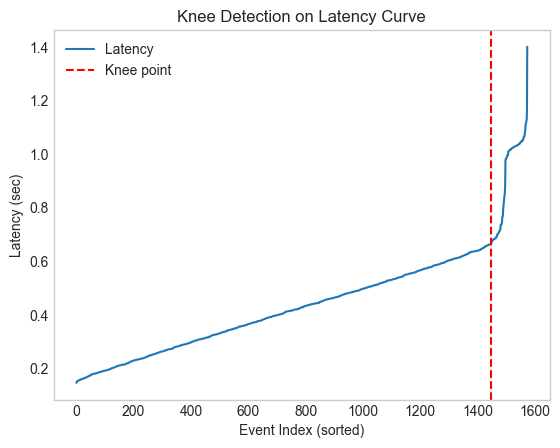

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# KNEE DETECTION ON LATENCY CURVE
# ============================================================

lat = np.sort(df["latency_sec"].values)

x = np.arange(len(lat))
y = lat

# normalize (important for stable knee detection)
x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (y - y.min()) / (y.max() - y.min())

# line between first and last point
p1 = np.array([x_norm[0], y_norm[0]])
p2 = np.array([x_norm[-1], y_norm[-1]])

line_vec = p2 - p1
line_vec = line_vec / np.linalg.norm(line_vec)

# compute distance of each point to line
distances = []

for i in range(len(x_norm)):
    point = np.array([x_norm[i], y_norm[i]])
    vec = point - p1

    proj = np.dot(vec, line_vec) * line_vec
    perp = vec - proj

    dist = np.linalg.norm(perp)
    distances.append(dist)

distances = np.array(distances)

# knee index = max distance
knee_index = np.argmax(distances)

knee_value = lat[knee_index]

print("\n================ KNEE DETECTION ================")
print(f"Knee index: {knee_index}")
print(f"Knee latency value: {knee_value:.4f} sec")
plt.figure()

plt.plot(lat, label="Latency")
plt.axvline(knee_index, color="red", linestyle="--", label="Knee point")

plt.title("Knee Detection on Latency Curve")
plt.xlabel("Event Index (sorted)")
plt.ylabel("Latency (sec)")
plt.legend()
plt.grid()

plt.show()

# Graph Ingestion Performance Analysis for Sysmon Event Processing Pipeline

## 1. Introduction

This study evaluates the performance of a Sysmon-to-Memgraph ingestion pipeline used for real-time security event processing. The objective is to analyze the scalability limitations of the original per-event ingestion architecture and evaluate the impact of batch graph insertion on throughput, latency, queue stability, and SLA compliance.

The analysis is based on:

* 1,574 Sysmon events
* measured wall-clock execution timings
* queueing theory
* SLA analysis
* utilization analysis
* latency tail analysis
* knee detection

The system was evaluated under two architectures:

1. **Streaming ingestion**
   One graph transaction per event.

2. **Batch ingestion**
   Multiple events grouped into a single graph transaction.

---

# 2. System Model

The graph ingestion stage is modeled as an M/G/1 queue:

| Component        | Description                                                     |
| ---------------- | --------------------------------------------------------------- |
| Arrivals         | Sysmon events generated by the monitored endpoint               |
| Server           | Single Memgraph writer                                          |
| Service time     | Time required to process one event or one amortized batch event |
| Queue discipline | FIFO                                                            |

System utilization is defined as:

\rho = \lambda \times E[S] = \frac{\lambda}{\mu}

Where:

* ( \lambda ) = arrival rate (events/sec)
* ( E[S] ) = average service time
* ( \mu ) = service rate

A single-server queue remains stable only when:

\rho < 1

---

# 3. Workload Characterization

The dataset contains 1,574 Sysmon events captured over a continuous monitoring interval.

| Metric                   | Value           |
| ------------------------ | --------------- |
| Total events             | 1,574           |
| Capture duration         | ~323 sec        |
| Arrival rate ( \lambda ) | 4.87 events/sec |

The workload includes:

* process creation events
* file creation events
* network connection events
* Docker-related activity
* browser processes
* command execution events

The event stream exhibits bursty arrival behavior typical of endpoint telemetry systems.

---

# 4. Streaming Architecture Analysis

## 4.1 Original Design

In the original architecture, each event triggered multiple independent Cypher transactions:

* process template upsert
* process instance merge
* artifact merge
* relationship creation
* graph edge creation

Typical operation counts:

| Event Type         | Cypher Round Trips |
| ------------------ | ------------------ |
| Process creation   | 6–8                |
| Network connection | 4                  |
| File creation      | 4                  |

For 1,574 events, the pipeline generated approximately:

```text id="dfn74a"
6,000–12,000 individual Cypher transactions
```

Each transaction incurred:

* TCP round-trip overhead
* query parsing overhead
* transaction commit cost
* synchronization latency

The dominant cost therefore became fixed transaction overhead rather than graph computation itself.

---

## 4.2 Streaming Performance Metrics

Measured performance:

| Metric                   | Value            |
| ------------------------ | ---------------- |
| Avg service time         | 1.403 sec/event  |
| Service rate ( \mu )     | 0.712 events/sec |
| Arrival rate ( \lambda ) | 4.874 events/sec |
| Utilization ( \rho )     | 6.842            |

Utilization calculation:

\rho = 4.87 \times 1.403 \approx 6.84

Since:

```text id="an0fy5"
ρ >> 1
```

the queue becomes mathematically unstable.

---

## 4.3 Queue Explosion

The unstable utilization caused continuous backlog accumulation:

| Queue Metric     | Value        |
| ---------------- | ------------ |
| Avg waiting time | 945.87 sec   |
| Max waiting time | 1,885.96 sec |
| P95 waiting time | 1,790.37 sec |
| Avg latency      | 947.28 sec   |
| Max queue size   | 1,342 events |

At peak load:

```text id="2cx7pi"
85% of all events were simultaneously waiting in queue
```

rather than being processed.

This demonstrates that the system became:

```text id="s8w4hx"
queueing-limited rather than processing-limited
```

The dominant component of latency was no longer graph execution but queue waiting time.

---

# 5. Batch Graph Ingestion

## 5.1 Optimization Strategy

To reduce transaction overhead, graph operations were grouped into batches.

Instead of:

```text id="kz5gmy"
1 event → 1 transaction
```

the optimized pipeline performs:

```text id="w4crgq"
N events → 1 transaction
```

This amortizes:

* transaction commits
* query parsing
* network round trips
* synchronization overhead

across multiple events.

---

# 6. Batch System Analysis — 2 Second Timeout

## 6.1 Batch Characteristics

Initial batch configuration:

| Parameter        | Value |
| ---------------- | ----- |
| Batch size limit | 100   |
| Flush timeout    | 2 sec |

Observed behavior:

| Metric                    | Value |
| ------------------------- | ----- |
| Avg batch size            | 15.90 |
| Median batch size         | 2     |
| Max batch size            | 53    |
| Timeout-triggered flushes | 99    |
| Size-triggered flushes    | 0     |

The workload arrival rate was insufficient to fill batches before timeout expiration. Flushes were therefore dominated by timeout-triggered execution.

---

## 6.2 Performance Results

Measured performance:

| Metric                   | Value            |
| ------------------------ | ---------------- |
| Avg processing time      | 0.156 sec/event  |
| Service rate ( \mu )     | 6.389 events/sec |
| Arrival rate ( \lambda ) | 4.818 events/sec |
| Utilization ( \rho )     | 0.754            |

Utilization:

\rho = \frac{4.82}{6.39} \approx 0.754

The queue became stable because:

```text id="q1g8ew"
ρ < 1
```

---

## 6.3 Latency and SLA Analysis

Latency metrics:

| Metric           | Value     |
| ---------------- | --------- |
| Avg waiting time | 1.419 sec |
| Avg latency      | 1.576 sec |
| P95 latency      | 4.617 sec |
| Max latency      | 5.587 sec |

SLA evaluation (2 sec threshold):

| Metric         | Value |
| -------------- | ----- |
| SLA threshold  | 2 sec |
| Violation rate | 24.7% |

The system was now stable, but latency remained elevated due to batching delay.

Events frequently waited for timeout expiration before flush execution.

---

# 7. Knee Detection Analysis

Latency knee detection was applied to identify the transition point where latency begins increasing rapidly.

Detected knee:

| Metric       | Value      |
| ------------ | ---------- |
| Knee index   | 1,111      |
| Knee latency | 1.5647 sec |

The knee point represents:

* the boundary between normal latency growth and tail amplification
* the onset of queue-dominated behavior
* the beginning of unstable tail dynamics

This value provides an operational threshold for safe system tuning.

---

# 8. Final Optimized Batch Configuration

The batching strategy was further refined to reduce timeout-induced waiting.

Final measurements:

| Metric               | Value     |
| -------------------- | --------- |
| Avg waiting time     | 0.248 sec |
| Avg processing time  | 0.199 sec |
| Avg latency          | 0.447 sec |
| P95 latency          | 0.849 sec |
| Max latency          | 1.399 sec |
| SLA violations       | 0%        |
| Utilization ( \rho ) | 0.885     |

---

# 9. Interpretation of Final Results

The final system achieved:

* stable utilization
* bounded queue growth
* sub-second latency
* zero SLA violations

Although utilization increased from:

```text id="az2r9x"
0.754 → 0.885
```

performance improved substantially.

This is because:

* batching delay was reduced
* service efficiency remained high
* queue growth remained bounded

The system therefore moved closer to full resource utilization while remaining stable.

Operating near:

```text id="ik0r8f"
0.7 ≤ ρ ≤ 0.9
```

is generally considered an efficient operating region for real-time systems.

---

# 10. Comparative Analysis

| Metric               | Streaming    | Final Batch |
| -------------------- | ------------ | ----------- |
| Avg service time     | 1.403 sec    | 0.199 sec   |
| Avg waiting time     | 945.87 sec   | 0.248 sec   |
| Avg latency          | 947.28 sec   | 0.447 sec   |
| P95 latency          | 1,790 sec    | 0.849 sec   |
| Utilization ( \rho ) | 6.84         | 0.885       |
| SLA violations       | catastrophic | 0%          |

Processing speedup:

\text{Speedup} = \frac{1.403}{0.199} \approx 7.06\times

---

# 11. Key Findings

The analysis demonstrates several critical results:

## 11.1 Streaming Architecture Was Fundamentally Unstable

The original system operated in a mathematically unstable regime:

```text id="nq6g94"
ρ > 1
```

This inevitably caused unbounded queue growth.

---

## 11.2 Queue Delay Dominated End-to-End Latency

The majority of total latency originated from waiting time rather than graph computation.

The system therefore became queueing-limited.

---

## 11.3 Batch Ingestion Eliminated Fixed Transaction Overhead

Batching amortized transaction cost across multiple events, dramatically reducing effective service time.

---

## 11.4 Batching Restored Queue Stability

Reducing service time lowered utilization below 1, stabilizing the queue.

---

## 11.5 Timeout Tuning Was Essential

Although batching restored stability, excessive timeout values introduced artificial latency.

Further timeout optimization eliminated SLA violations.

---

# 12. Conclusion

This study demonstrates that the original per-event graph ingestion architecture could not sustain the observed Sysmon event rate due to excessive transaction overhead and unstable queue utilization.

By introducing batch graph insertion:

* transaction overhead was amortized
* service rate increased significantly
* utilization dropped below the stability threshold
* queue growth became bounded
* real-time performance became feasible

The final optimized configuration achieved:

* sub-second average latency
* zero SLA violations
* stable queue dynamics
* efficient resource utilization

The results confirm that batch graph ingestion is an effective architectural optimization for scalable real-time telemetry processing systems.
